Mesh table: h = 0.1
i	x_i	y_i	exact y(x_i)	signed error	absolute error
0	0.000	0.9872559200	1.0000000000	-1.27441e-02	1.27441e-02
1	0.100	0.8929674333	0.9048374180	-1.18700e-02	1.18700e-02
2	0.200	0.8075531570	0.8187307531	-1.11776e-02	1.11776e-02
3	0.300	0.7301490235	0.7408182207	-1.06692e-02	1.06692e-02
4	0.400	0.6599686447	0.6703200460	-1.03514e-02	1.03514e-02
5	0.500	0.5962949345	0.6065306597	-1.02357e-02	1.02357e-02
6	0.600	0.5384723059	0.5488116361	-1.03393e-02	1.03393e-02
7	0.700	0.4858993440	0.4965853038	-1.06860e-02	1.06860e-02
8	0.800	0.4380218460	0.4493289641	-1.13071e-02	1.13071e-02
9	0.900	0.3943261238	0.4065696597	-1.22435e-02	1.22435e-02
10	1.000	0.3543324546	0.3678794412	-1.35470e-02	1.35470e-02
Mesh table: h = 0.05
i	x_i	y_i	exact y(x_i)	signed error	absolute error
0	0.000	0.9966309764	1.0000000000	-3.36902e-03	3.36902e-03
1	0.050	0.9479827625	0.9512294245	-3.24666e-03	3.24666e-03
2	0.100	0.9017012185	0.9048374180	-3.13620e-03	3.13620e-03
3	0.150	0.8576703708	0.8607079

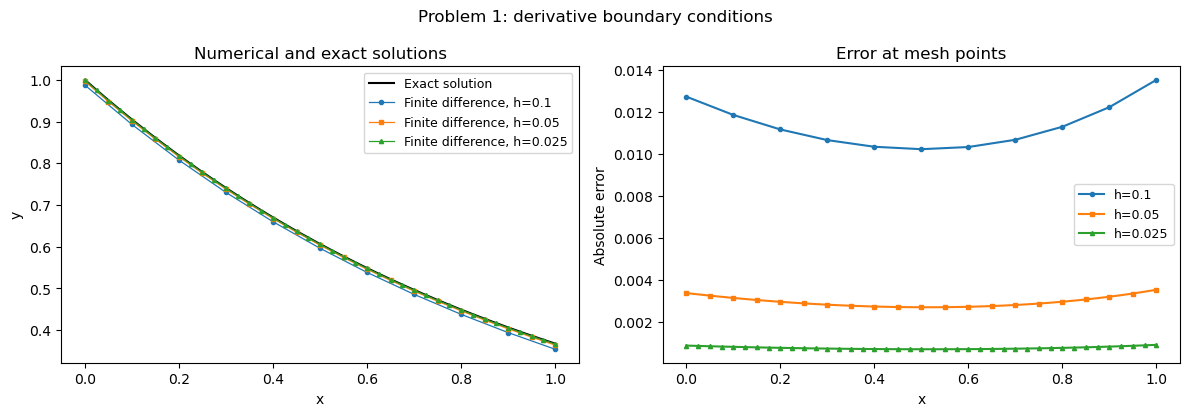

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

def save_op(n):
    text_path = Path(f"Q{n}.txt")
    text_path.write_text("", encoding="utf-8")
    plt_n = 0

    def print_r(*args, **kwargs):
        print(*args, **kwargs)
        with text_path.open("a", encoding="utf-8") as output:
            print(*args, file=output, **kwargs)

    def show_plt():
        nonlocal plt_n
        plt_n += 1
        path = Path(f"Q{n}_plot_{plt_n:02d}.png")
        plt.savefig(path, bbox_inches="tight")
        plt.show()

    return print_r, show_plt

print_r, show_plt = save_op(1)


def table(headers, rows):
    print_r(*headers, sep="\t")
    for row in rows:
        print_r(*row, sep="\t")


HS = (0.1, 0.05, 0.025)
X_FINE = np.linspace(0, 1, 10001)


def uniform_mesh(h):
    M = int(round(1.0/h))
    return np.linspace(0.0, 1.0, M + 1)


def mesh_table(x, y, exact):
    truth = exact(x)
    table(["i", "x_i", "y_i", "exact y(x_i)", "signed error", "absolute error"],
          [[i, f"{xi:.3f}", f"{yi:.10f}", f"{ti:.10f}",
            f"{yi-ti:+.5e}", f"{abs(yi-ti):.5e}"]
           for i, (xi, yi, ti) in enumerate(zip(x, y, truth))])


def convergence_table(results, exact):
    errors = [float(np.max(np.abs(r["y"] - exact(r["x"])))) for r in results]
    rows = []
    for k, (r, error) in enumerate(zip(results, errors)):
        ratio = "-" if k == 0 else f"{errors[k-1]/error:.6f}"
        order = "-" if k == 0 else f"{np.log2(errors[k-1]/error):.6f}"
        rows.append([f'{r["h"]:.3f}', len(r["x"]) - 1,
                     f"{error:.8e}", ratio, order])
    table(["h", "M", "E_h", "E_previous/E_h", "observed order p"], rows)
    return np.array(errors)


def plot_fd(results, exact, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    axes[0].plot(X_FINE, exact(X_FINE), "k-", label="Exact solution")
    markers = ("o", "s", "^")
    for r, marker in zip(results, markers):
        x, y, h = r["x"], r["y"], r["h"]
        axes[0].plot(x, y, marker=marker, markersize=3, linewidth=0.9,
                     label=f"Finite difference, h={h:g}")
        axes[1].plot(x, np.abs(y - exact(x)), marker=marker, markersize=3,
                     label=f"h={h:g}")
    axes[0].set(xlabel="x", ylabel="y", title="Numerical and exact solutions")
    axes[1].set(xlabel="x", ylabel="Absolute error", title="Error at mesh points")
    for ax in axes:
        ax.legend(fontsize=9)
    fig.suptitle(title)
    fig.tight_layout()
    show_plt()


def exact_robin(x):
    return np.exp(-x)


def solve_fd_robin(h):
    x = uniform_mesh(h)
    M = len(x) - 1
    A = np.zeros((M + 1, M + 1))
    b = np.zeros(M + 1)

    A[0, 0:3] = [2*h - 3, 4.0, -1.0]
    A[M, M-2:M+1] = [-1.0, 4.0, 2*h - 3]
    b[M] = 4*h/np.e

    for i in range(1, M):
        A[i, i-1] = 1 + h/2
        A[i, i] = -(2 + 2*h*h)
        A[i, i+1] = 1 - h/2

    y = np.linalg.solve(A, b)
    return {"h": h, "x": x, "y": y, "A": A, "b": b}


fd1 = [solve_fd_robin(h) for h in HS]
for r in fd1:
    print_r(f'Mesh table: h = {r["h"]:g}')
    mesh_table(r["x"], r["y"], exact_robin)

print_r("Convergence")
errors1 = convergence_table(fd1, exact_robin)
plot_fd(fd1, exact_robin, "Problem 1: derivative boundary conditions")

h = 0.1: A Y = b, with Y = (y_1,...,y_9)^T
A =
 [[-2.01  1.    0.    0.    0.    0.    0.    0.    0.  ]
 [ 1.   -2.01  1.    0.    0.    0.    0.    0.    0.  ]
 [ 0.    1.   -2.01  1.    0.    0.    0.    0.    0.  ]
 [ 0.    0.    1.   -2.01  1.    0.    0.    0.    0.  ]
 [ 0.    0.    0.    1.   -2.01  1.    0.    0.    0.  ]
 [ 0.    0.    0.    0.    1.   -2.01  1.    0.    0.  ]
 [ 0.    0.    0.    0.    0.    1.   -2.01  1.    0.  ]
 [ 0.    0.    0.    0.    0.    0.    1.   -2.01  1.  ]
 [ 0.    0.    0.    0.    0.    0.    0.    1.   -2.01]]
b = [0.001 0.002 0.003 0.004 0.005 0.006 0.007 0.008 0.009]
Mesh table: h = 0.1
i	x_i	y_i	exact y(x_i)	signed error	absolute error
0	0.000	0.0000000000	0.0000000000	+0.00000e+00	0.00000e+00
1	0.100	-0.0147553114	-0.0147662966	+1.09852e-05	1.09852e-05
2	0.200	-0.0286581759	-0.0286795456	+2.13697e-05	2.13697e-05
3	0.300	-0.0408476221	-0.0408781619	+3.05398e-05	3.05398e-05
4	0.400	-0.0504455446	-0.0504833998	+3.78552e-05	3.78552e-05
5	0.

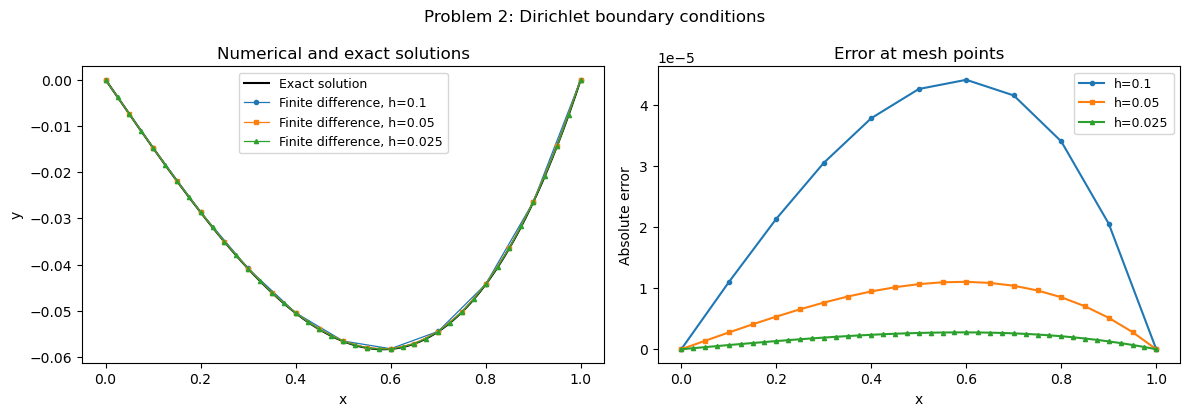

In [2]:
print_r, show_plt = save_op(2)


def exact_dirichlet(x):
    return np.sinh(x)/np.sinh(1.0) - x


def solve_fd_dirichlet(h):
    x = uniform_mesh(h)
    M = len(x) - 1
    A = np.zeros((M - 1, M - 1))
    b = np.zeros(M - 1)
    for row in range(M - 1):
        i = row + 1
        A[row, row] = -(2 + h*h)
        if row > 0:
            A[row, row-1] = 1.0
        if row < M - 2:
            A[row, row+1] = 1.0
        b[row] = h*h*x[i]

    y = np.zeros(M + 1)
    y[1:M] = np.linalg.solve(A, b)
    return {"h": h, "x": x, "y": y, "A": A, "b": b}


fd2 = [solve_fd_dirichlet(h) for h in HS]
print_r("h = 0.1: A Y = b, with Y = (y_1,...,y_9)^T")
print_r("A =\n", fd2[0]["A"])
print_r("b =", fd2[0]["b"])
for r in fd2:
    print_r(f'Mesh table: h = {r["h"]:g}')
    mesh_table(r["x"], r["y"], exact_dirichlet)

print_r("Convergence")
errors2 = convergence_table(fd2, exact_dirichlet)
plot_fd(fd2, exact_dirichlet, "Problem 2: Dirichlet boundary conditions")

h = 0.1: 5 Newton iterations
Newton update	max change	max scaled residual |F_i|
1	1.068702e+00	1.142125e-02
2	6.388810e-02	4.081690e-05
3	2.301320e-04	5.296077e-10
4	2.890892e-09	3.885781e-16
5	0.000000e+00	3.885781e-16
i	x_i	y_i	exact y(x_i)	signed error	absolute error
0	0.000	6.0000000000	6.0000000000	+0.00000e+00	0.00000e+00
1	0.100	4.9634837365	4.9586776860	+4.80605e-03	4.80605e-03
2	0.200	4.1733291809	4.1666666667	+6.66251e-03	6.66251e-03
3	0.300	3.5573413899	3.5502958580	+7.04553e-03	7.04553e-03
4	0.400	3.0679003766	3.0612244898	+6.67589e-03	6.67589e-03
5	0.500	2.6725794904	2.6666666667	+5.91282e-03	5.91282e-03
6	0.600	2.3486854156	2.3437500000	+4.93542e-03	4.93542e-03
7	0.700	2.0799545725	2.0761245675	+3.83001e-03	3.83001e-03
8	0.800	1.8544858398	1.8518518519	+2.63399e-03	2.63399e-03
9	0.900	1.6634082843	1.6620498615	+1.35842e-03	1.35842e-03
10	1.000	1.5000000000	1.5000000000	+0.00000e+00	0.00000e+00
h = 0.05: 5 Newton iterations
Newton update	max change	max scaled residual |F_i

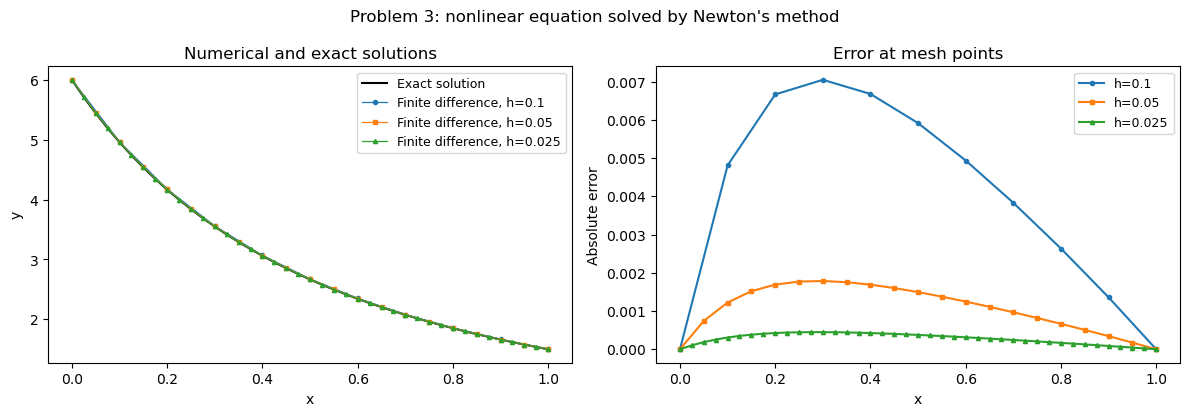

In [3]:
print_r, show_plt = save_op(3)


NEWTON_TOL = 1e-10


def exact_nonlinear(x):
    return 6.0/(1.0 + x)**2


def nonlinear_residual_jacobian(u, h):
    n = len(u)
    y = np.empty(n + 2)
    y[0], y[-1] = 6.0, 1.5
    y[1:-1] = u
    F = np.zeros(n)
    J = np.zeros((n, n))
    for row in range(n):
        i = row + 1
        F[row] = y[i-1] - 2*y[i] + y[i+1] - h*h*y[i]**2
        J[row, row] = -2 - 2*h*h*y[i]
        if row > 0:
            J[row, row-1] = 1.0
        if row < n - 1:
            J[row, row+1] = 1.0
    return F, J


def solve_fd_nonlinear(h, tol=NEWTON_TOL, max_iter=100):
    x = uniform_mesh(h)
    u = 6.0 - 4.5*x[1:-1]
    history = []
    for iteration in range(1, max_iter + 1):
        F, J = nonlinear_residual_jacobian(u, h)
        delta = np.linalg.solve(J, -F)
        u_new = u + delta
        step = float(np.max(np.abs(u_new - u)))
        F_new, _ = nonlinear_residual_jacobian(u_new, h)
        residual = float(np.max(np.abs(F_new)))
        history.append((iteration, step, residual))
        u = u_new
        if step < tol:
            y = np.empty(len(x))
            y[0], y[-1] = 6.0, 1.5
            y[1:-1] = u
            return {"h": h, "x": x, "y": y,
                    "iterations": iteration, "history": history}


fd3 = [solve_fd_nonlinear(h) for h in HS]
for r in fd3:
    print_r(f'h = {r["h"]:g}: {r["iterations"]} Newton iterations')
    table(["Newton update", "max change", "max scaled residual |F_i|"],
          [[k, f"{step:.6e}", f"{residual:.6e}"]
           for k, step, residual in r["history"]])
    mesh_table(r["x"], r["y"], exact_nonlinear)

print_r("Discretization error and convergence")
errors3 = convergence_table(fd3, exact_nonlinear)
plot_fd(fd3, exact_nonlinear, "Problem 3: nonlinear equation solved by Newton's method")

Coefficients in ascending powers: c_0, ..., c_N
N	c_0	c_1	c_2	c_3	c_4	c_5	c_6	c_7
3	9.6409784583e-01	-9.6409784583e-01	4.4324622324e-01	-1.0745362988e-01	-	-	-	-
4	9.9739624147e-01	-9.9739624147e-01	4.9249385248e-01	-1.5236528561e-01	2.4624692624e-02	-	-	-
5	9.9966733127e-01	-9.9966733127e-01	4.9924713500e-01	-1.6470515831e-01	3.8128989074e-02	-5.0788341706e-03	-	-
6	9.9998820673e-01	-9.9998820673e-01	4.9994810492e-01	-1.6646563284e-01	4.1161053970e-02	-7.6226603475e-03	8.4399292603e-04	-
7	9.9999883815e-01	-9.9999883815e-01	4.9999644824e-01	-1.6665023390e-01	4.1613348410e-02	-8.2301701099e-03	1.2697108730e-03	-1.2065729864e-04
N	max absolute error on 10,001 points
3	3.5902154171e-02
4	3.1261816808e-03
5	3.3266872846e-04
6	1.4582545673e-05
7	1.1618474389e-06


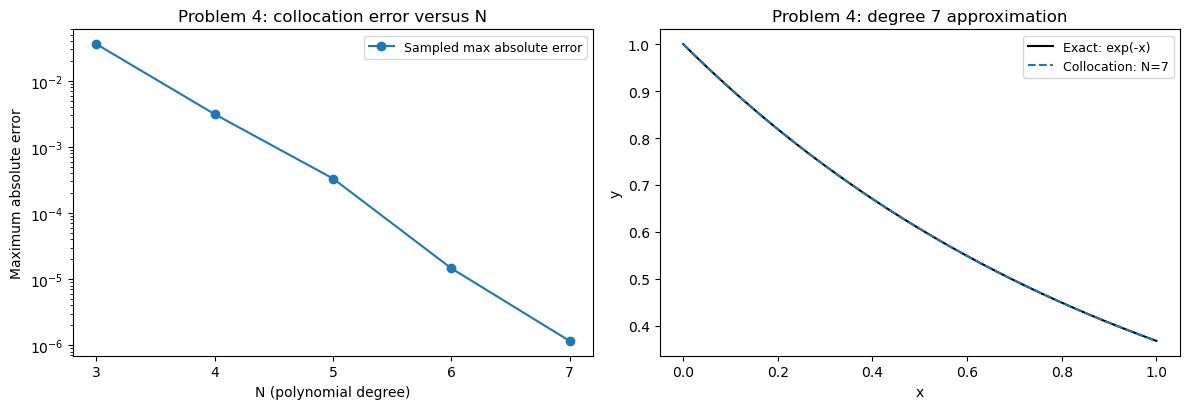

In [4]:
print_r, show_plt = save_op(4)


def monomial(j, x, derivative=0):
    x = np.asarray(x, dtype=float)
    if derivative == 0:
        return x**j
    if derivative == 1:
        return np.zeros_like(x) if j == 0 else j*x**(j-1)
    if derivative == 2:
        return np.zeros_like(x) if j < 2 else j*(j-1)*x**(j-2)


def eval_poly(c, x, derivative=0):
    values = np.zeros_like(np.asarray(x, dtype=float))
    for j, cj in enumerate(c):
        values += cj*monomial(j, x, derivative)
    return values


def solve_collocation_robin(N):
    points = np.array([k/N for k in range(1, N)])
    A = np.zeros((N + 1, N + 1))
    b = np.zeros(N + 1)
    A[0, 0], A[0, 1] = 1.0, 1.0
    for row, xk in enumerate(points, start=1):
        for j in range(N + 1):
            A[row, j] = (monomial(j, xk, 2) - monomial(j, xk, 1)
                         - 2*monomial(j, xk))
    for j in range(N + 1):
        A[N, j] = 1 - j
    b[N] = 2/np.e
    c = np.linalg.solve(A, b)
    error = float(np.max(np.abs(eval_poly(c, X_FINE) - exact_robin(X_FINE))))
    return {"N": N, "c": c, "points": points, "A": A, "b": b, "error": error}


coll4 = [solve_collocation_robin(N) for N in range(3, 8)]
print_r("Coefficients in ascending powers: c_0, ..., c_N")
table(["N"] + [f"c_{j}" for j in range(8)],
      [[r["N"]] + [f'{r["c"][j]:.10e}' if j <= r["N"] else "-"
                     for j in range(8)] for r in coll4])
table(["N", "max absolute error on 10,001 points"],
      [[r["N"], f'{r["error"]:.10e}'] for r in coll4])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].semilogy([r["N"] for r in coll4], [r["error"] for r in coll4], "o-",
                 label="Sampled max absolute error")
axes[0].set(xlabel="N (polynomial degree)", ylabel="Maximum absolute error",
            title="Problem 4: collocation error versus N", xticks=range(3, 8))
axes[1].plot(X_FINE, exact_robin(X_FINE), "k-", label="Exact: exp(-x)")
axes[1].plot(X_FINE, eval_poly(coll4[-1]["c"], X_FINE), "--",
             label="Collocation: N=7")
axes[1].set(xlabel="x", ylabel="y", title="Problem 4: degree 7 approximation")
for ax in axes:
    ax.legend(fontsize=9)
fig.tight_layout()
show_plt()

Coefficients for x^i(1-x): c_1, ..., c_N
N	c_1	c_2	c_3	c_4	c_5	c_6
2	-1.4464285714e-01	-1.6071428571e-01	-	-	-	-
3	-1.5018437421e-01	-1.4304390393e-01	-1.8572257690e-02	-	-	-
4	-1.4904401388e-01	-1.4932456371e-01	-6.5758657379e-03	-8.0361046108e-03	-	-
5	-1.4908767333e-01	-1.4902793308e-01	-7.4804344797e-03	-6.8142787998e-03	-6.1870553054e-04	-
6	-1.4908173154e-01	-1.4908333473e-01	-7.2546534341e-03	-7.2826461368e-03	-1.4154303882e-04	-1.9119178881e-04
N	max absolute error on 10,001 points
2	5.8105151902e-04
3	6.3081021296e-05
4	2.4792041279e-06
5	2.1458505762e-07
6	5.8747427999e-09


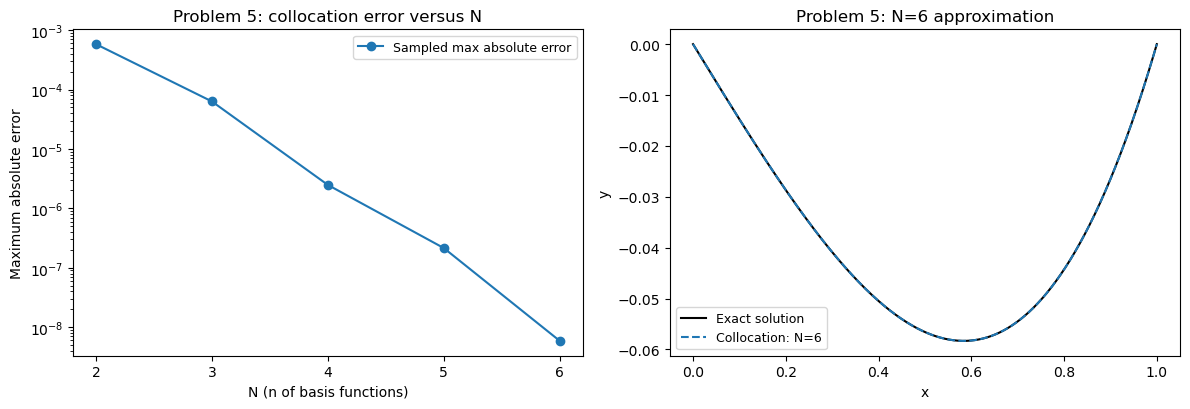

FD h	FD interior unknowns	FD max error at nodes	N=6 collocation error at same nodes	N=6 collocation fine-mesh error	FD error/collocation error at same nodes
0.1	9	4.41459147e-05	5.86360691e-09	5.87474280e-09	7528.80
0.05	19	1.10468911e-05	5.86360691e-09	5.87474280e-09	1883.98
0.025	39	2.76237451e-06	5.86360691e-09	5.87474280e-09	471.10
The N=6 collocation system has 6 unknown coefficients.


In [5]:
print_r, show_plt = save_op(5)


def dirichlet_basis(i, x, derivative=0):
    return monomial(i, x, derivative) - monomial(i+1, x, derivative)


def evalute_dirichlet(c, x, derivative=0):
    values = np.zeros_like(np.asarray(x, dtype=float))
    for i, ci in enumerate(c, start=1):
        values += ci*dirichlet_basis(i, x, derivative)
    return values


def solve_collocation_dirichlet(N):
    points = np.array([k/(N+1) for k in range(1, N+1)])
    A = np.zeros((N, N))
    b = np.zeros(N)
    for row, xk in enumerate(points):
        b[row] = xk
        for col in range(N):
            i = col + 1
            A[row, col] = dirichlet_basis(i, xk, 2) - dirichlet_basis(i, xk)
    c = np.linalg.solve(A, b)
    error = float(np.max(np.abs(evalute_dirichlet(c, X_FINE)
                                - exact_dirichlet(X_FINE))))
    return {"N": N, "c": c, "points": points, "A": A, "b": b, "error": error}


coll5 = [solve_collocation_dirichlet(N) for N in range(2, 7)]
print_r("Coefficients for x^i(1-x): c_1, ..., c_N")
table(["N"] + [f"c_{i}" for i in range(1, 7)],
      [[r["N"]] + [f'{r["c"][i-1]:.10e}' if i <= r["N"] else "-"
                     for i in range(1, 7)] for r in coll5])
table(["N", "max absolute error on 10,001 points"],
      [[r["N"], f'{r["error"]:.10e}'] for r in coll5])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].semilogy([r["N"] for r in coll5], [r["error"] for r in coll5], "o-",
                 label="Sampled max absolute error")
axes[0].set(xlabel="N (n of basis functions)", ylabel="Maximum absolute error",
            title="Problem 5: collocation error versus N", xticks=range(2, 7))
axes[1].plot(X_FINE, exact_dirichlet(X_FINE), "k-", label="Exact solution")
axes[1].plot(X_FINE, evalute_dirichlet(coll5[-1]["c"], X_FINE), "--",
             label="Collocation: N=6")
axes[1].set(xlabel="x", ylabel="y", title="Problem 5: N=6 approximation")
for ax in axes:
    ax.legend(fontsize=9)
fig.tight_layout()
show_plt()


c6 = coll5[-1]["c"]
comparison_rows = []
for h in HS:
    r = solve_fd_dirichlet(h)
    fd_error = float(np.max(np.abs(r["y"] - exact_dirichlet(r["x"]))))
    coll_at_fd_nodes = float(np.max(np.abs(evalute_dirichlet(c6, r["x"])
                                          - exact_dirichlet(r["x"]))))
    comparison_rows.append([f'{r["h"]:g}', len(r["x"])-2,
                            f"{fd_error:.8e}", f"{coll_at_fd_nodes:.8e}",
                            f'{coll5[-1]["error"]:.8e}',
                            f"{fd_error/coll_at_fd_nodes:.2f}"])
table(["FD h", "FD interior unknowns", "FD max error at nodes",
       "N=6 collocation error at same nodes", "N=6 collocation fine-mesh error",
       "FD error/collocation error at same nodes"], comparison_rows)
print_r("The N=6 collocation system has 6 unknown coefficients.")